In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [2]:
data=pd.read_csv('project1.csv')
data.head()

,Engine Capacity (liters),Cylinders,Drive Type,Fuel Tank Capacity (liters),Fuel Economy (L/100 Km),Fuel Type,Horsepower (bhp),Torque (Nm),Transmission,Top Speed (Km/h),Seating Capacity,Acceleration 0-100 Km/h (sec),Length (meters),Width (meters),Height (meters),Wheelbase (meters),Trunk Capacity (liters),name,price,currency
0,1.2,3.0,Front Wheel Drive,42,4.9,Petrol,76,100,Automatic,170,5 Seater,14.0,4.245,1.670,1.515,2.550,450,Mitsubishi Attrage 2021 1.2 GLX (Base),"34,099",SAR
1,1.2,3.0,Front Wheel Drive,42,4.9,Petrol,76,100,Automatic,170,5 Seater,14.0,4.245,1.670,1.515,2.550,450,Mitsubishi Attrage 2021 1.2 GLX (Base),"34,099",SAR
2,1.4,4.0,Front Wheel Drive,45,6.3,Petrol,75,118,Manual,156,2 Seater,16.0,3.864,1.716,1.721,2.513,2800,Fiat Fiorino 2021 1.4L Standard,"41,250",SAR
3,1.6,4.0,Front Wheel Drive,50,6.4,Petrol,102,145,Automatic,180,5 Seater,11.0,4.354,1.994,1.529,2.635,510,Renault Symbol 2021 1.6L PE,"44,930",SAR
4,1.5,4.0,Front Wheel Drive,48,5.8,Petrol,112,150,Automatic,170,5 Seater,10.9,4.314,1.809,1.624,2.585,448,MG ZS 2021 1.5L STD,"57,787",SAR


In [3]:
data.shape

(5668, 20)

In [4]:
data.isnull().sum()

Engine Capacity (liters)           0
Cylinders                        703
Drive Type                         0
Fuel Tank Capacity (liters)        0
Fuel Economy (L/100 Km)            0
Fuel Type                          0
Horsepower (bhp)                   0
Torque (Nm)                        0
Transmission                       0
Top Speed (Km/h)                   0
Seating Capacity                   0
Acceleration 0-100 Km/h (sec)      0
Length (meters)                    0
Width (meters)                     0
Height (meters)                    0
Wheelbase (meters)                 0
Trunk Capacity (liters)           12
name                               0
price                              0
currency                           0
dtype: int64

In [5]:
data= data.dropna()

In [6]:
data = pd.get_dummies(data, columns=['Drive Type', 'Transmission','Fuel Type'], drop_first=True)

In [7]:
data = data.drop(columns=['name','currency','price','Seating Capacity','Trunk Capacity (liters)','Fuel Tank Capacity (liters)','Fuel Economy (L/100 Km)'])
data.head()

,Engine Capacity (liters),Cylinders,Horsepower (bhp),Torque (Nm),Top Speed (Km/h),Acceleration 0-100 Km/h (sec),Length (meters),Width (meters),Height (meters),Wheelbase (meters),Drive Type_Front Wheel Drive,Drive Type_Rear Wheel Drive,Transmission_CVT,Transmission_Manual,Fuel Type_Hybrid,Fuel Type_Petrol
0,1.2,3.0,76,100,170,14.0,4.245,1.670,1.515,2.550,True,False,False,False,False,True
1,1.2,3.0,76,100,170,14.0,4.245,1.670,1.515,2.550,True,False,False,False,False,True
2,1.4,4.0,75,118,156,16.0,3.864,1.716,1.721,2.513,True,False,False,True,False,True
3,1.6,4.0,102,145,180,11.0,4.354,1.994,1.529,2.635,True,False,False,False,False,True
4,1.5,4.0,112,150,170,10.9,4.314,1.809,1.624,2.585,True,False,False,False,False,True


In [8]:
data['Torque (Nm)'].max()

'96'

(array([ 24.,  30.,  34.,  14.,  10.,  40.,  13.,  24.,  45., 159.,   7.,
         15.,  11.,  28.,  13.,  17.,  17.,  27.,  16.,  24.,  29.,  69.,
        244.,  18.,  30.,  26.,  62.,   6.,  54.,   3.,  90.,   2.,  13.,
         29.,  30.,   4.,   2.,   2.,  27., 163.,  10.,  65.,  25.,  95.,
         22.,  46.,   4.,  24.,   8.,  19.,  18.,   1.,  28.,  94.,  44.,
          3.,  30.,  21., 178.,  32.,  28.,  25.,  33.,  31.,  19.,  26.,
         14., 136.,  10.,  70.,  36.,  16.,   6.,  48.,  19.,  23.,  17.,
         10.,  23.,   6.,   6.,  12.,  26.,  46.,  35.,  34.,  38.,  15.,
         62.,   2.,  13.,  44.,  50.,   6.,  81.,  36.,  29.,  82.,  72.,
         41.,  27.,  19.,  12.,  18.,  27., 124.,  11.,   1.,  82.,  16.,
          5.,  16.,  28.,  62.,  36., 111.,  15.,  28.,  40.,  12.,  28.,
         29.,  36.,  56.,   4.,  13.,  42.,   5.,  13.,   2.,   6.,  15.,
          2.,   6.,  20.,   5.,   3.,   4.,   6.,   5.,   2.,   4.,   5.,
          4.,   7.,   4.,   4.,  13., 

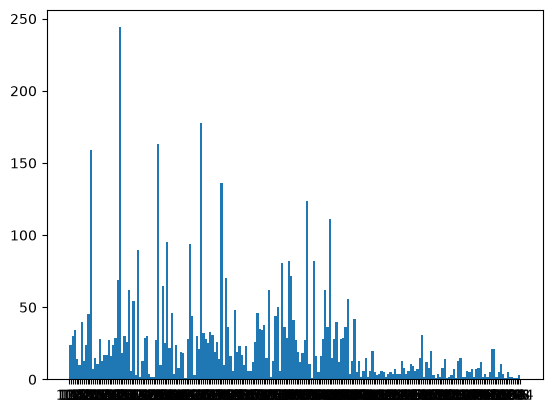

In [9]:
plt.hist(data['Torque (Nm)'], bins=200)

In [ ]:
import numpy as np

numeric_cols = ['Engine Capacity (liters)','Cylinders','Horsepower (bhp)','Torque (Nm)',
                'Acceleration 0-100 Km/h (sec)','Length (meters)','Width (meters)',
                'Height (meters)','Wheelbase (meters)']

for col in numeric_cols:
    data[col] = data[col].astype(str)
    data[col] = data[col].str.replace(r'[^\d.]', '', regex=True)
    data[col] = data[col].str.replace(' ', '')
    data[col] = data[col].replace('', np.nan)
    data[col] = data[col].astype(float)

data = data.dropna(subset=numeric_cols)


In [11]:
data = data[data['Engine Capacity (liters)'] >= 1.0]
data = data[data['Horsepower (bhp)'] <= 2000]
data = data[data['Top Speed (Km/h)'] <= 400.0]
data = data[data['Length (meters)'] <= 10.0]
data = data[data['Width (meters)'] <= 5.0]
data = data[data['Height (meters)'] <= 5.0]
data = data[data['Wheelbase (meters)'] <= 5.0]

In [12]:
max_speed = data['Top Speed (Km/h)'].max()
for j in range(0,5668):
    for i in data.iloc[j:j+1].to_dict(orient='records'):
        if i['Top Speed (Km/h)'] == max_speed:
            print(i)    

{'Engine Capacity (liters)': 6.5, 'Cylinders': 12.0, 'Horsepower (bhp)': 770.0, 'Torque (Nm)': 720.0, 'Top Speed (Km/h)': 350, 'Acceleration 0-100 Km/h (sec)': 2.8, 'Length (meters)': 4.943, 'Width (meters)': 2.098, 'Height (meters)': 1.136, 'Wheelbase (meters)': 2.7, 'Drive Type_Front Wheel Drive': False, 'Drive Type_Rear Wheel Drive': False, 'Transmission_CVT': False, 'Transmission_Manual': False, 'Fuel Type_Hybrid': False, 'Fuel Type_Petrol': True}
{'Engine Capacity (liters)': 6.5, 'Cylinders': 12.0, 'Horsepower (bhp)': 770.0, 'Torque (Nm)': 720.0, 'Top Speed (Km/h)': 350, 'Acceleration 0-100 Km/h (sec)': 2.8, 'Length (meters)': 4.343, 'Width (meters)': 2.098, 'Height (meters)': 1.136, 'Wheelbase (meters)': 2.7, 'Drive Type_Front Wheel Drive': False, 'Drive Type_Rear Wheel Drive': False, 'Transmission_CVT': False, 'Transmission_Manual': False, 'Fuel Type_Hybrid': False, 'Fuel Type_Petrol': True}
{'Engine Capacity (liters)': 3.8, 'Cylinders': 6.0, 'Horsepower (bhp)': 600.0, 'Torque (

In [13]:
numerical_features = [
    'Engine Capacity (liters)',
    'Cylinders',
    'Horsepower (bhp)',
    'Torque (Nm)',
    'Acceleration 0-100 Km/h (sec)',
    'Length (meters)',
    'Width (meters)',
    'Height (meters)',
    'Wheelbase (meters)'
]

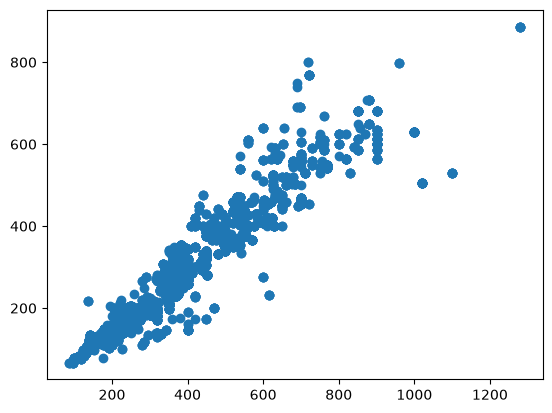

In [14]:
plt.scatter(data['Torque (Nm)'], data['Horsepower (bhp)'])

In [15]:
data = data.drop(columns=['Acceleration 0-100 Km/h (sec)'])
numerical_features.remove('Acceleration 0-100 Km/h (sec)')

In [16]:
import statsmodels.api as sm
p = data[numerical_features]
e = data['Top Speed (Km/h)']
X_train_sm = sm.add_constant(p)
model = sm.OLS(e, X_train_sm).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       Top Speed (Km/h)   R-squared:                       0.824
Model:                            OLS   Adj. R-squared:                  0.824
Method:                 Least Squares   F-statistic:                     2876.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:38:18   Log-Likelihood:                -21142.
No. Observations:                4924   AIC:                         4.230e+04
Df Residuals:                    4915   BIC:                         4.236e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [17]:
scaler = StandardScaler()
data[numerical_features] = scaler.fit_transform(data[numerical_features])

In [18]:
data.head()

,Engine Capacity (liters),Cylinders,Horsepower (bhp),Torque (Nm),Top Speed (Km/h),Length (meters),Width (meters),Height (meters),Wheelbase (meters),Drive Type_Front Wheel Drive,Drive Type_Rear Wheel Drive,Transmission_CVT,Transmission_Manual,Fuel Type_Hybrid,Fuel Type_Petrol
0,-1.341576,-1.331038,-1.480301,-1.567410,170,-1.241774,-1.875204,-0.291133,-1.075432,True,False,False,False,False,True
1,-1.341576,-1.331038,-1.480301,-1.567410,170,-1.241774,-1.875204,-0.291133,-1.075432,True,False,False,False,False,True
2,-1.196244,-0.811413,-1.487164,-1.472514,156,-2.140913,-1.504884,0.715154,-1.220666,True,False,False,True,False,True
3,-1.050912,-0.811413,-1.301870,-1.330170,180,-0.984540,0.733137,-0.222745,-0.741785,True,False,False,False,False,True
4,-1.123578,-0.811413,-1.233242,-1.303811,170,-1.078938,-0.756193,0.241320,-0.938048,True,False,False,False,False,True


In [19]:
features = [
    'Engine Capacity (liters)',
    'Cylinders',
    'Drive Type',
    'Horsepower (bhp)',
    'Torque (Nm)',
    'Transmission',
    'Length (meters)',
    'Width (meters)',
    'Height (meters)',
    'Wheelbase (meters)',
    'Fuel Type'
]

target = 'Top Speed (Km/h)'


In [20]:
from sklearn.model_selection import train_test_split

# Feature və target ayır
X = data.drop(columns=['Top Speed (Km/h)'])
y = data['Top Speed (Km/h)']

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
X_train.columns

Train shape: (3939, 14)
Test shape: (985, 14)


Index(['Engine Capacity (liters)', 'Cylinders', 'Horsepower (bhp)',
       'Torque (Nm)', 'Length (meters)', 'Width (meters)', 'Height (meters)',
       'Wheelbase (meters)', 'Drive Type_Front Wheel Drive',
       'Drive Type_Rear Wheel Drive', 'Transmission_CVT',
       'Transmission_Manual', 'Fuel Type_Hybrid', 'Fuel Type_Petrol'],
      dtype='str')

In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor

# Model yarat
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
#monotonic_cst=[0, 1, 1, 1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0]
# Predict
y_pred = rf.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("R2:", r2)

MAE: 1.407193951064337
R2: 0.9871757150637479


In [22]:
import pandas as pd

corr = pd.DataFrame(X).corrwith(pd.Series(y))
print(corr)

Engine Capacity (liters)        0.386327
Cylinders                       0.509606
Horsepower (bhp)                0.755949
Torque (Nm)                     0.687513
Length (meters)                 0.042637
Width (meters)                  0.230011
Height (meters)                -0.598565
Wheelbase (meters)              0.005527
Drive Type_Front Wheel Drive   -0.396498
Drive Type_Rear Wheel Drive     0.338565
Transmission_CVT               -0.091528
Transmission_Manual            -0.130754
Fuel Type_Hybrid                0.078594
Fuel Type_Petrol                0.046683
dtype: float64


In [23]:
numerical_features

['Engine Capacity (liters)',
 'Cylinders',
 'Horsepower (bhp)',
 'Torque (Nm)',
 'Length (meters)',
 'Width (meters)',
 'Height (meters)',
 'Wheelbase (meters)']

In [24]:
user_car = {
    'Engine Capacity (liters)': 10.0,
    'Cylinders': 8,
    'Horsepower (bhp)': 1600,
    'Torque (Nm)': 1500,
    'Length (meters)': 4.810,
    'Width (meters)': 2.030,
    'Height (meters)': 1.210,
    'Wheelbase (meters)': 2.7,
    'Drive Type_Front Wheel Drive': 0,       # one-hot encoded form
    'Drive Type_Rear Wheel Drive': 1,
    'Transmission_CVT': 0,
    'Transmission_Manual': 0,
    'Fuel Type_Hybrid': 0,
    'Fuel Type_Petrol': 1
}
user_df = pd.DataFrame([user_car])

# Align columns with training features
feature_columns = X_train.columns
for col in feature_columns:
    if col not in user_df.columns:
        user_df[col] = 0
user_df = user_df[feature_columns]

# Scale the numerical features
user_df[numerical_features] = scaler.transform(user_df[numerical_features])
X_train.columns

Index(['Engine Capacity (liters)', 'Cylinders', 'Horsepower (bhp)',
       'Torque (Nm)', 'Length (meters)', 'Width (meters)', 'Height (meters)',
       'Wheelbase (meters)', 'Drive Type_Front Wheel Drive',
       'Drive Type_Rear Wheel Drive', 'Transmission_CVT',
       'Transmission_Manual', 'Fuel Type_Hybrid', 'Fuel Type_Petrol'],
      dtype='str')

In [25]:
def feasibility_check(user_input, predicted_speed, max_dataset_speed=500, max_cylinders=16, max_length=10.0, max_width=3, max_height=4.0):    

    # Threshold → datasetdən təyin edə bilərik, burada sadə bir nümunə
    if predicted_speed > max_dataset_speed:
        return "Unrealistic"
    elif user_input['Cylinders'] >= max_cylinders:
        return "Unrealistic"
    elif user_input['Length (meters)'] > max_length or user_input['Width (meters)'] > max_width or user_input['Height (meters)'] > max_height: 
        return "Unrealistic"
    else:
        return "Realistic"


In [26]:
# Predict
pred_speed = rf.predict(user_df)[0]
# feasibility
feasibility = feasibility_check(user_car, pred_speed)
print(f"Predicted Top Speed: {pred_speed:.2f} km/h")
print("Feasibility:", feasibility)


Predicted Top Speed: 345.59 km/h
Feasibility: Realistic


In [27]:
y_subset = y_train.sample(n=985, random_state=42)  # pandas Series


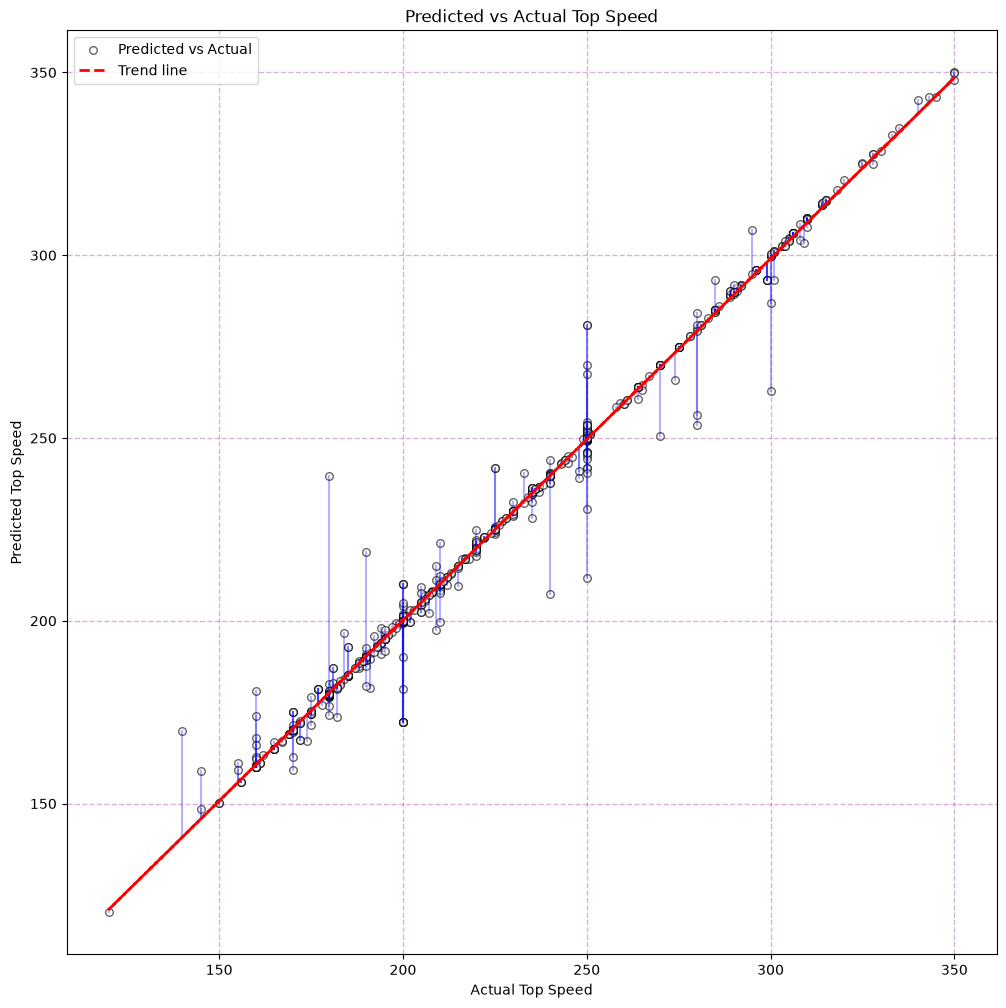

In [28]:
# scatter
plt.figure(figsize=(12,12))
plt.scatter(y_test, y_pred, s=30, color='white', label='Predicted vs Actual', alpha=0.6, edgecolor='black')
plt.xlabel('Actual Top Speed')
plt.ylabel('Predicted Top Speed')
plt.title('Predicted vs Actual Top Speed')
# trend line (scatter-in ortasından keçən xətt)
coeffs = np.polyfit(y_test, y_pred, 1)  # linear fit
m, b = coeffs

for x, y in zip(y_test, y_pred):
    plt.plot([x, x], [y, m*x+b], color='blue', alpha=0.3)  # hər nöqtədən trend xəttə dik xətt

plt.plot(y_test, m*y_test + b, 'r--', label='Trend line', linewidth=2)
plt.legend()
plt.grid(True, alpha=0.3, linestyle='--', linewidth=1, color='purple')

plt.show()


In [29]:
import pickle

# model obyektini fayla yazmaq
with open("rf_model.pkl", "wb") as f:
    pickle.dump(rf, f)

# scaler obyektini fayla yazmaq (əgər varsa)
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)